In [1]:
from google.colab import files
uploaded = files.upload()

Saving b6167dcf878645dab445c8328c514135.jpg to b6167dcf878645dab445c8328c514135.jpg


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

if image is None:
    raise ValueError("Unable to read image")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

In [3]:
# Define three original points
pts1 = np.float32([
    [50, 50],
    [200, 50],
    [50, 200]
])

# Define three destination points
pts2 = np.float32([
    [10, 100],
    [200, 50],
    [100, 250]
])

# Calculate affine transformation matrix
matrix = cv2.getAffineTransform(pts1, pts2)

# Apply transformation
affine_image = cv2.warpAffine(
    image,
    matrix,
    (width, height)
)

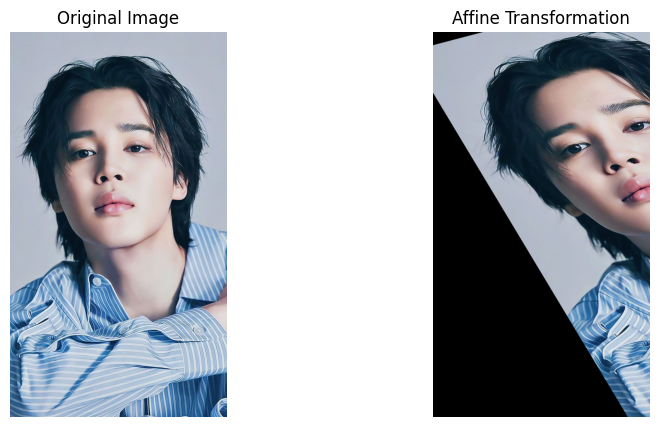

In [4]:
affine_rgb = cv2.cvtColor(
    affine_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(affine_rgb)
plt.title("Affine Transformation")
plt.axis("off")

plt.show()